# 01 - Explore CBIS-DDSM metadata (A2)

Goal: build one clean table (one row per ROI crop) for `~/data/cbis-ddsm/processed/rois.csv`.

Data lives outside the repo at `~/data/cbis-ddsm/` (`csv/` + `jpeg/`). Kaggle: "CBIS-DDSM: Breast Cancer Image Dataset" (awsaf49), JPEG version.

In [18]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from PIL import Image

DATA = Path.home() / "data" / "cbis-ddsm"
CSV = DATA / "csv"
JPEG = DATA / "jpeg"

# sanity check: do the paths exist?
print(CSV.exists(), JPEG.exists())
print(sorted(p.name for p in CSV.iterdir()))

True True
['calc_case_description_test_set.csv', 'calc_case_description_train_set.csv', 'dicom_info.csv', 'mass_case_description_test_set.csv', 'mass_case_description_train_set.csv', 'meta.csv']


## 1. Case description CSVs (mass / calc x train / test)

Findings:
- Mass files have `mass shape`, `mass margins`; calc files have `calc type`, `calc distribution`. The other 12 columns are the same.
- Density column name differs: `breast_density` (mass) vs `breast density` (calc). Must standardize before concatenating.
- Path columns: `image file path`, `cropped image file path`, `ROI mask file path` (the last three columns).

In [19]:
# load the four case files into separate DataFrames
mass_train = pd.read_csv(CSV / 'mass_case_description_train_set.csv')
mass_test = pd.read_csv(CSV / 'mass_case_description_test_set.csv')
calc_train = pd.read_csv(CSV / 'calc_case_description_train_set.csv')
calc_test = pd.read_csv(CSV / 'calc_case_description_test_set.csv')

# for each of the four, print shape, columns, and 3 rows
for name, case_df in [('mass_train', mass_train), ('mass_test', mass_test),
                      ('calc_train', calc_train), ('calc_test', calc_test)]:
    print(name, case_df.shape)
    print(case_df.columns.tolist())
    display(case_df.head(3))

mass_train (1318, 14)
['patient_id', 'breast_density', 'left or right breast', 'image view', 'abnormality id', 'abnormality type', 'mass shape', 'mass margins', 'assessment', 'pathology', 'subtlety', 'image file path', 'cropped image file path', 'ROI mask file path']


,patient_id,breast_density,left or right breast,image view,abnormality id,abnormality type,mass shape,mass margins,assessment,pathology,subtlety,image file path,cropped image file path,ROI mask file path
0,P_00001,3,LEFT,CC,1,mass,IRREGULAR-ARCHITECTURAL_DISTORTION,SPICULATED,4,MALIGNANT,4,Mass-Training_P_00001_LEFT_CC/1.3.6.1.4.1.9590...,Mass-Training_P_00001_LEFT_CC_1/1.3.6.1.4.1.95...,Mass-Training_P_00001_LEFT_CC_1/1.3.6.1.4.1.95...
1,P_00001,3,LEFT,MLO,1,mass,IRREGULAR-ARCHITECTURAL_DISTORTION,SPICULATED,4,MALIGNANT,4,Mass-Training_P_00001_LEFT_MLO/1.3.6.1.4.1.959...,Mass-Training_P_00001_LEFT_MLO_1/1.3.6.1.4.1.9...,Mass-Training_P_00001_LEFT_MLO_1/1.3.6.1.4.1.9...
2,P_00004,3,LEFT,CC,1,mass,ARCHITECTURAL_DISTORTION,ILL_DEFINED,4,BENIGN,3,Mass-Training_P_00004_LEFT_CC/1.3.6.1.4.1.9590...,Mass-Training_P_00004_LEFT_CC_1/1.3.6.1.4.1.95...,Mass-Training_P_00004_LEFT_CC_1/1.3.6.1.4.1.95...


mass_test (378, 14)
['patient_id', 'breast_density', 'left or right breast', 'image view', 'abnormality id', 'abnormality type', 'mass shape', 'mass margins', 'assessment', 'pathology', 'subtlety', 'image file path', 'cropped image file path', 'ROI mask file path']


,patient_id,breast_density,left or right breast,image view,abnormality id,abnormality type,mass shape,mass margins,assessment,pathology,subtlety,image file path,cropped image file path,ROI mask file path
0,P_00016,4,LEFT,CC,1,mass,IRREGULAR,SPICULATED,5,MALIGNANT,5,Mass-Test_P_00016_LEFT_CC/1.3.6.1.4.1.9590.100...,Mass-Test_P_00016_LEFT_CC_1/1.3.6.1.4.1.9590.1...,Mass-Test_P_00016_LEFT_CC_1/1.3.6.1.4.1.9590.1...
1,P_00016,4,LEFT,MLO,1,mass,IRREGULAR,SPICULATED,5,MALIGNANT,5,Mass-Test_P_00016_LEFT_MLO/1.3.6.1.4.1.9590.10...,Mass-Test_P_00016_LEFT_MLO_1/1.3.6.1.4.1.9590....,Mass-Test_P_00016_LEFT_MLO_1/1.3.6.1.4.1.9590....
2,P_00017,2,LEFT,CC,1,mass,ROUND,CIRCUMSCRIBED,4,MALIGNANT,4,Mass-Test_P_00017_LEFT_CC/1.3.6.1.4.1.9590.100...,Mass-Test_P_00017_LEFT_CC_1/1.3.6.1.4.1.9590.1...,Mass-Test_P_00017_LEFT_CC_1/1.3.6.1.4.1.9590.1...


calc_train (1546, 14)
['patient_id', 'breast density', 'left or right breast', 'image view', 'abnormality id', 'abnormality type', 'calc type', 'calc distribution', 'assessment', 'pathology', 'subtlety', 'image file path', 'cropped image file path', 'ROI mask file path']


,patient_id,breast density,left or right breast,image view,abnormality id,abnormality type,calc type,calc distribution,assessment,pathology,subtlety,image file path,cropped image file path,ROI mask file path
0,P_00005,3,RIGHT,CC,1,calcification,AMORPHOUS,CLUSTERED,3,MALIGNANT,3,Calc-Training_P_00005_RIGHT_CC/1.3.6.1.4.1.959...,Calc-Training_P_00005_RIGHT_CC_1/1.3.6.1.4.1.9...,Calc-Training_P_00005_RIGHT_CC_1/1.3.6.1.4.1.9...
1,P_00005,3,RIGHT,MLO,1,calcification,AMORPHOUS,CLUSTERED,3,MALIGNANT,3,Calc-Training_P_00005_RIGHT_MLO/1.3.6.1.4.1.95...,Calc-Training_P_00005_RIGHT_MLO_1/1.3.6.1.4.1....,Calc-Training_P_00005_RIGHT_MLO_1/1.3.6.1.4.1....
2,P_00007,4,LEFT,CC,1,calcification,PLEOMORPHIC,LINEAR,4,BENIGN,4,Calc-Training_P_00007_LEFT_CC/1.3.6.1.4.1.9590...,Calc-Training_P_00007_LEFT_CC_1/1.3.6.1.4.1.95...,Calc-Training_P_00007_LEFT_CC_1/1.3.6.1.4.1.95...


calc_test (326, 14)
['patient_id', 'breast density', 'left or right breast', 'image view', 'abnormality id', 'abnormality type', 'calc type', 'calc distribution', 'assessment', 'pathology', 'subtlety', 'image file path', 'cropped image file path', 'ROI mask file path']


,patient_id,breast density,left or right breast,image view,abnormality id,abnormality type,calc type,calc distribution,assessment,pathology,subtlety,image file path,cropped image file path,ROI mask file path
0,P_00038,2,LEFT,CC,1,calcification,PUNCTATE-PLEOMORPHIC,CLUSTERED,4,BENIGN,2,Calc-Test_P_00038_LEFT_CC/1.3.6.1.4.1.9590.100...,Calc-Test_P_00038_LEFT_CC_1/1.3.6.1.4.1.9590.1...,Calc-Test_P_00038_LEFT_CC_1/1.3.6.1.4.1.9590.1...
1,P_00038,2,LEFT,MLO,1,calcification,PUNCTATE-PLEOMORPHIC,CLUSTERED,4,BENIGN,2,Calc-Test_P_00038_LEFT_MLO/1.3.6.1.4.1.9590.10...,Calc-Test_P_00038_LEFT_MLO_1/1.3.6.1.4.1.9590....,Calc-Test_P_00038_LEFT_MLO_1/1.3.6.1.4.1.9590....
2,P_00038,2,RIGHT,CC,1,calcification,VASCULAR,NaN,2,BENIGN_WITHOUT_CALLBACK,5,Calc-Test_P_00038_RIGHT_CC/1.3.6.1.4.1.9590.10...,Calc-Test_P_00038_RIGHT_CC_1/1.3.6.1.4.1.9590....,Calc-Test_P_00038_RIGHT_CC_1/1.3.6.1.4.1.9590....


## 2. `dicom_info.csv`

Findings:
- 10,237 rows, one per JPEG. `image_path` looks like `CBIS-DDSM/jpeg/<SeriesUID>/<n>-<m>.jpg`; on this machine that is `~/data/cbis-ddsm/jpeg/<SeriesUID>/...`.
- `SeriesDescription` counts: cropped images 3567, ROI mask images 3247, full mammogram images 2857.
- 566 rows have a **blank** `SeriesDescription` (`value_counts()` hides them by default, which explains 9,671 vs 10,237).

In [20]:
dicom = pd.read_csv(CSV / 'dicom_info.csv')
print(dicom.shape, dicom.columns)
display(dicom.head(3))
print(dicom['SeriesDescription'].value_counts())
print(dicom['image_path'].head())

(10237, 38) Index(['file_path', 'image_path', 'AccessionNumber', 'BitsAllocated',
       'BitsStored', 'BodyPartExamined', 'Columns', 'ContentDate',
       'ContentTime', 'ConversionType', 'HighBit', 'InstanceNumber',
       'LargestImagePixelValue', 'Laterality', 'Modality', 'PatientBirthDate',
       'PatientID', 'PatientName', 'PatientOrientation', 'PatientSex',
       'PhotometricInterpretation', 'PixelRepresentation',
       'ReferringPhysicianName', 'Rows', 'SOPClassUID', 'SOPInstanceUID',
       'SamplesPerPixel', 'SecondaryCaptureDeviceManufacturer',
       'SecondaryCaptureDeviceManufacturerModelName', 'SeriesDescription',
       'SeriesInstanceUID', 'SeriesNumber', 'SmallestImagePixelValue',
       'SpecificCharacterSet', 'StudyDate', 'StudyID', 'StudyInstanceUID',
       'StudyTime'],
      dtype='str')


,file_path,image_path,AccessionNumber,BitsAllocated,BitsStored,BodyPartExamined,Columns,ContentDate,ContentTime,ConversionType,...,SecondaryCaptureDeviceManufacturerModelName,SeriesDescription,SeriesInstanceUID,SeriesNumber,SmallestImagePixelValue,SpecificCharacterSet,StudyDate,StudyID,StudyInstanceUID,StudyTime
0,CBIS-DDSM/dicom/1.3.6.1.4.1.9590.100.1.2.12930...,CBIS-DDSM/jpeg/1.3.6.1.4.1.9590.100.1.2.129308...,NaN,16,16,BREAST,351,20160426,131732.685,WSD,...,MATLAB,cropped images,1.3.6.1.4.1.9590.100.1.2.129308726812851964007...,1,23078,ISO_IR 100,20160720.0,DDSM,1.3.6.1.4.1.9590.100.1.2.271867287611061855725...,214951.0
1,CBIS-DDSM/dicom/1.3.6.1.4.1.9590.100.1.2.24838...,CBIS-DDSM/jpeg/1.3.6.1.4.1.9590.100.1.2.248386...,NaN,16,16,BREAST,3526,20160426,143829.101,WSD,...,MATLAB,full mammogram images,1.3.6.1.4.1.9590.100.1.2.248386742010678582309...,1,0,ISO_IR 100,20160720.0,DDSM,1.3.6.1.4.1.9590.100.1.2.161516517311681906612...,193426.0
2,CBIS-DDSM/dicom/1.3.6.1.4.1.9590.100.1.2.26721...,CBIS-DDSM/jpeg/1.3.6.1.4.1.9590.100.1.2.267213...,NaN,16,16,BREAST,1546,20160503,111956.298,WSD,...,MATLAB,full mammogram images,1.3.6.1.4.1.9590.100.1.2.267213171011171858918...,1,0,ISO_IR 100,20160807.0,DDSM,1.3.6.1.4.1.9590.100.1.2.291043622711253836701...,161814.0


SeriesDescription
cropped images           3567
ROI mask images          3247
full mammogram images    2857
Name: count, dtype: int64
0    CBIS-DDSM/jpeg/1.3.6.1.4.1.9590.100.1.2.129308...
1    CBIS-DDSM/jpeg/1.3.6.1.4.1.9590.100.1.2.248386...
2    CBIS-DDSM/jpeg/1.3.6.1.4.1.9590.100.1.2.267213...
3    CBIS-DDSM/jpeg/1.3.6.1.4.1.9590.100.1.2.381187...
4    CBIS-DDSM/jpeg/1.3.6.1.4.1.9590.100.1.2.381187...
Name: image_path, dtype: str


## 3. Mapping case-CSV paths to JPEGs

Case path format: `<patient folder>/<StudyUID>/<SeriesUID>/000000.dcm`. The **SeriesUID** (second to last part) matches `SeriesInstanceUID` in `dicom_info`.

Checked on `mass_train` row 0: the cropped path (`000000.dcm`) and the ROI mask path (`000001.dcm`) point to the **same series**, so joining on series UID returns two rows (one cropped, one ROI mask). They must be separated with `SeriesDescription` (JPEG file names like `1-250.jpg` / `2-249.jpg` do not match `000000`/`000001`).
For this case the crop is 515x431 and the mask is full-size 4808x3024; opening both images confirmed the labels.

In [21]:
print(mass_train.loc[0, 'cropped image file path'])
print(mass_train.loc[0, 'ROI mask file path'])

Mass-Training_P_00001_LEFT_CC_1/1.3.6.1.4.1.9590.100.1.2.108268213011361124203859148071588939106/1.3.6.1.4.1.9590.100.1.2.296736403313792599626368780122205399650/000000.dcm
Mass-Training_P_00001_LEFT_CC_1/1.3.6.1.4.1.9590.100.1.2.108268213011361124203859148071588939106/1.3.6.1.4.1.9590.100.1.2.296736403313792599626368780122205399650/000001.dcm



series UID: 1.3.6.1.4.1.9590.100.1.2.296736403313792599626368780122205399650


,image_path,SeriesDescription,Rows,Columns
8025,CBIS-DDSM/jpeg/1.3.6.1.4.1.9590.100.1.2.296736...,ROI mask images,4808,3024
8026,CBIS-DDSM/jpeg/1.3.6.1.4.1.9590.100.1.2.296736...,cropped images,515,431


ROI mask images 1-250.jpg (3024, 4808) exists: True
cropped images 2-249.jpg (431, 515) exists: True


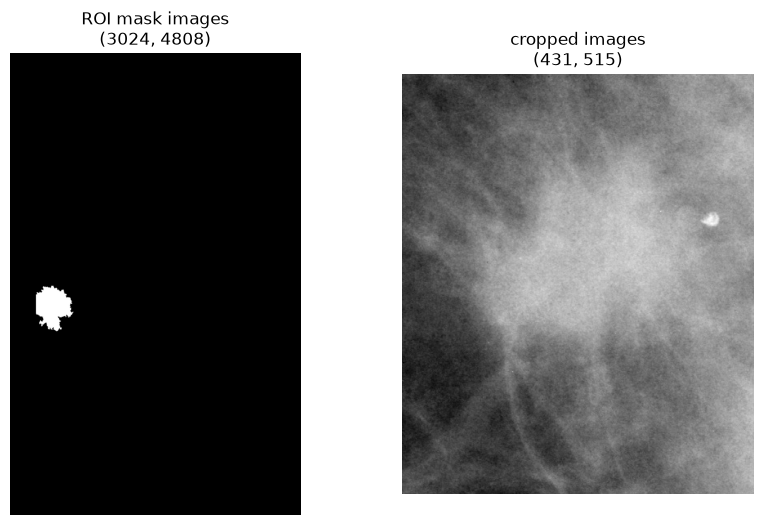

566 blank rows


,Rows,Columns
count,566.000000,566.000000
mean,5147.722615,3001.005300
std,682.476824,525.110256
min,3880.000000,1801.000000
25%,4584.000000,2682.000000
50%,5063.500000,2958.000000
75%,5491.000000,3168.000000
max,6871.000000,4966.000000


In [22]:
# 1. Pull the series UID out of the case path.
#    Path = <patient folder>/<StudyUID>/<SeriesUID>/000000.dcm, so the series UID is second to last.
crop_path = mass_train.loc[0, 'cropped image file path']
uid = crop_path.split('/')[-2]
print("series UID:", uid)

# 2. Find the matching rows in dicom_info.
match = dicom[dicom['SeriesInstanceUID'] == uid]
display(match[['image_path', 'SeriesDescription', 'Rows', 'Columns']])

# 3. Convert each CSV path to a real path on your Mac, then open and show the images.
fig, axes = plt.subplots(1, len(match), figsize=(10, 6))
for ax, (_, row) in zip(axes, match.iterrows()):
    jpg = JPEG / row['image_path'].replace('CBIS-DDSM/jpeg/', '')
    img = Image.open(jpg)
    print(row['SeriesDescription'], jpg.name, img.size, "exists:", jpg.exists())
    ax.imshow(img, cmap='gray')
    ax.set_title(f"{row['SeriesDescription']}\n{img.size}")
    ax.axis('off')
plt.show()

# 4. Look at the rows with a blank SeriesDescription.
blank = dicom[dicom['SeriesDescription'].isna()]
print(len(blank), "blank rows")
display(blank[['image_path', 'Rows', 'Columns']].describe())

1-015.jpg (2952, 4512) exists: True
1-176.jpg (3120, 4608) exists: True
1-283.jpg (3196, 5431) exists: True
2-189.jpg (2311, 4726) exists: True


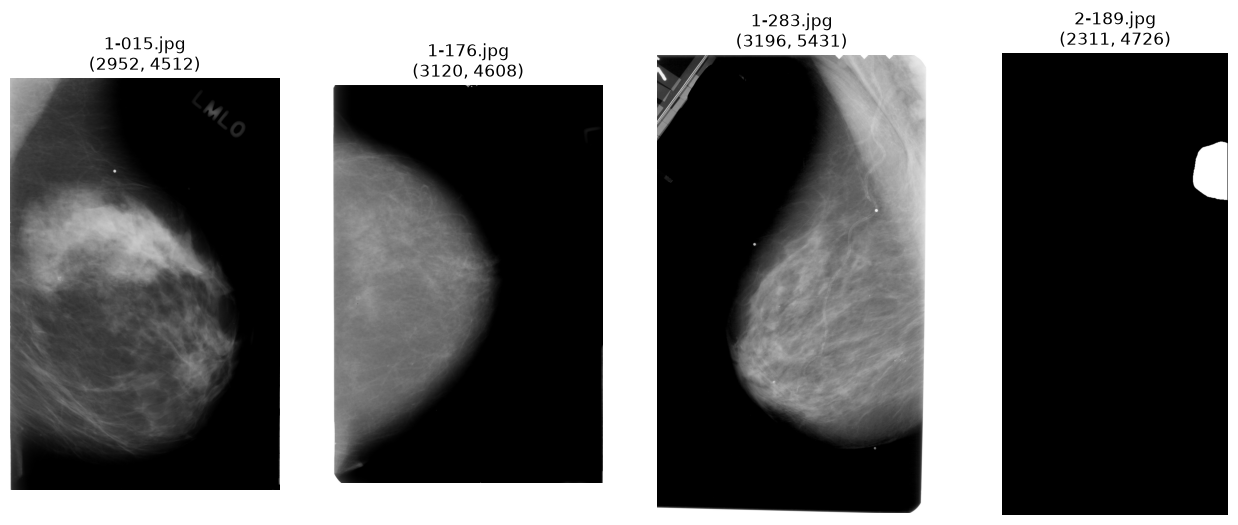

In [23]:
sample = blank.sample(4, random_state=0)
fig, axes = plt.subplots(1, len(sample), figsize=(16, 6))
for ax, (_, row) in zip(axes, sample.iterrows()):
    jpg = JPEG / row['image_path'].replace('CBIS-DDSM/jpeg/', '')
    img = Image.open(jpg)
    print(jpg.name, img.size, "exists:", jpg.exists())
    ax.imshow(img, cmap='gray')
    ax.set_title(f"{jpg.name}\n{img.size}")
    ax.axis('off')
plt.show()

In [24]:
# Series UIDs that have a 'cropped images' row in dicom_info
crop_uids = set(
    dicom.loc[dicom['SeriesDescription'] == 'cropped images', 'SeriesInstanceUID']
)

for name, case_df in [('mass_train', mass_train), ('mass_test', mass_test),
                      ('calc_train', calc_train), ('calc_test', calc_test)]:
    # series UID = second-to-last piece of the cropped image path
    uids = case_df['cropped image file path'].str.strip().str.split('/').str[-2]
    found = uids.isin(crop_uids)
    print(f"{name}: expected {len(case_df)}, found {found.sum()}, missing {(~found).sum()}")

mass_train: expected 1318, found 1318, missing 0
mass_test: expected 378, found 378, missing 0
calc_train: expected 1546, found 1544, missing 2
calc_test: expected 326, found 326, missing 0


In [25]:
row = calc_train.loc[344]

for col in ['cropped image file path', 'ROI mask file path']:
    uid = row[col].strip().split('/')[-2]
    print(col, '->', uid)
    display(dicom.loc[dicom['SeriesInstanceUID'] == uid,
                      ['SeriesDescription', 'Rows', 'Columns']])

cropped image file path -> 1.3.6.1.4.1.9590.100.1.2.27611247910023474515584644283556391565


,SeriesDescription,Rows,Columns
5484,ROI mask images,5326,3301


ROI mask file path -> 1.3.6.1.4.1.9590.100.1.2.323173986211744534717152497940376023803


,SeriesDescription,Rows,Columns
2708,cropped images,1129,1065


### Decision: cropped vs ROI mask paths, and the two problem rows in `calc_train`

**Finding.** The case CSVs sometimes point the "cropped image file path" at the wrong series. Checked on `calc_train` row 344 (`P_00474`, MALIGNANT):
- `cropped image file path` -> series labeled `ROI mask images` in `dicom_info` (5326 x 3301, full-image size).
- `ROI mask file path` -> series labeled `cropped images` (1129 x 1065, a lesion crop).

So the two column names are swapped for this row. Trusting the column name would feed a full-size mask to the model as a crop. Separately, the path strings contain a trailing newline, so they must be `.strip()`ed before splitting.

**Rule.** Do not trust the column names. For each case row:
1. Strip each path and take its series UID (second-to-last piece after splitting on `/`).
2. Look up both UIDs (cropped path and ROI path) in `dicom_info.csv`.
3. The crop is the `dicom_info` row with `SeriesDescription == 'cropped images'`; the mask is the one labeled `ROI mask images`.

Because the label comes from `dicom_info` and not from the CSV column, row 344 is recovered automatically.

**Row 1216 (`P_01563`, BENIGN_WITHOUT_CALLBACK, abnormality 2).** Its series UID has no rows in `dicom_info.csv`, so no JPEG exists in this download. Decision: **drop this row** from `rois.csv` and record the drop in the findings. Keeping it with a missing path would break the Dataset at load time, and there is nothing to recover. Expected effect: 1 fewer training example (1,545 of 1,546 calc_train rows remain).

**Check after building `rois.csv`.** Every `roi_path` must exist on disk, and each ROI crop's size should be small (hundreds of pixels), not full-image size (thousands).

In [26]:
# pathology count 
for name, case_df in [('mass_train', mass_train), ('mass_test', mass_test),
                      ('calc_train', calc_train), ('calc_test', calc_test)]:
    print(name)
    print(case_df['pathology'].value_counts(dropna=False))
    print()

mass_train
pathology
MALIGNANT                  637
BENIGN                     577
BENIGN_WITHOUT_CALLBACK    104
Name: count, dtype: int64

mass_test
pathology
BENIGN                     194
MALIGNANT                  147
BENIGN_WITHOUT_CALLBACK     37
Name: count, dtype: int64

calc_train
pathology
MALIGNANT                  544
BENIGN                     528
BENIGN_WITHOUT_CALLBACK    474
Name: count, dtype: int64

calc_test
pathology
BENIGN                     130
MALIGNANT                  129
BENIGN_WITHOUT_CALLBACK     67
Name: count, dtype: int64



### Label decision
`pathology` has exactly three values in all four files (no missing or misspelled values). Rule for the binary task:
- `MALIGNANT` -> 1 (malignant)
- `BENIGN` and `BENIGN_WITHOUT_CALLBACK` -> 0 (benign)

Reason: `BENIGN_WITHOUT_CALLBACK` is a benign finding that did not need follow-up, so for benign vs. malignant it belongs with benign. The original 3-class column is kept as `pathology_raw` in `rois.csv` so the decision can be revisited.

Class balance (before dropping any rows): train 1,181 malignant of 2,864 (about 41%); test 276 malignant of 704 (about 39%). Moderately imbalanced, not extreme.

In [27]:
# overlap between the train and test
# one set of patients IDs per split (mass + calc combined)

train_ids = set(mass_train['patient_id']) | set(calc_train['patient_id'])
test_ids = set(mass_test['patient_id']) | set(calc_test['patient_id'])

overlap = train_ids & test_ids 
print('unique patients train:', len(train_ids),
        'test:', len(test_ids), 
        ' in both: ', len(overlap))
print('examples:', sorted(overlap)[:10])


unique patients train: 1248 test: 349  in both:  31
examples: ['P_00016', 'P_00041', 'P_00159', 'P_00394', 'P_00495', 'P_00510', 'P_00591', 'P_00601', 'P_00639', 'P_00652']


In [28]:
# where the overlap comes from, file by file 

files = {
    'mass_train': mass_train, 'mass_test': mass_test,
    'calc_train': calc_train, 'calc_test': calc_test,
}
ids = {name: set(df_['patient_id']) for name, df_ in files.items()}

pairs = [
    ('mass_train', 'calc_train'),   # same split, different type (allowed)
    ('mass_test',  'calc_test'),    # same split, different type (allowed)
    ('mass_train', 'mass_test'),    # same type, train vs test
    ('calc_train', 'calc_test'),    # same type, train vs test
    ('mass_train', 'calc_test'),    # cross type, train vs test
    ('calc_train', 'mass_test'),    # cross type, train vs test
]
for a, b in pairs:
    print(f"{a} & {b}: {len(ids[a] & ids[b])}")


mass_train & calc_train: 45
mass_test & calc_test: 3
mass_train & mass_test: 0
calc_train & calc_test: 0
mass_train & calc_test: 13
calc_train & mass_test: 18


In [29]:
# check the ID format is consistent

all_ids = pd.concat([mass_train, mass_test, calc_train, calc_test])['patient_id']
print(all_ids.str.match(r'^P_\d{5}$').all())   # True means every ID looks like P_00001

True


### Patient overlap between official train and test

Patient IDs are consistently formatted (`P_00001` style, checked with a regex on all four files), so the overlap below is real, not a matching artifact.

| | count |
|---|---|
| unique patients in train (mass + calc) | 1,248 |
| unique patients in test (mass + calc) | 349 |
| patients in **both** train and test | **31** |

Where the 31 come from (patients shared between files):
- `mass_train` & `mass_test`: 0
- `calc_train` & `calc_test`: 0
- `mass_train` & `calc_test`: 13
- `calc_train` & `mass_test`: 18
- (13 + 18 = 31, so the two groups do not overlap each other.)

Also: 45 patients appear in both `mass_train` and `calc_train`, and 3 in both `mass_test` and `calc_test`. That is expected, since a patient can have both a mass and a calcification.

**Interpretation.** The official split keeps patients separate *within* each lesion type (0 overlap mass-vs-mass and calc-vs-calc), but not *across* types: 31 patients (about 9% of test patients) have one lesion type in train and the other in test. The model could therefore see tissue from the same patient during training, which may make test AUC somewhat optimistic. I have not measured how much.

**Decisions.**
1. Keep the official split for the baseline, so results stay comparable with other work on CBIS-DDSM, and report this overlap in the README.
2. In A5, also report test AUC with these 31 patients excluded, as a sensitivity check.
3. In A3, build the validation split with `GroupShuffleSplit` on `patient_id` over the **combined** mass + calc train table (not per file), so a patient with both lesion types never ends up on both sides of train/val.

In [30]:
# standardize and stack the four files 
files = {
    'mass_train': mass_train, 'mass_test': mass_test,
    'calc_train': calc_train, 'calc_test': calc_test,
}

parts = []
for name, case_df in files.items():
    part = case_df.copy()                       # never modify the originals
    part['split'] = name.split('_')[1]          # 'train' or 'test'
    part['source'] = name                       # keep for debugging
    part = part.rename(columns={'breast_density': 'breast density'})   # mass files only; harmless for calc
    parts.append(part)

cases = pd.concat(parts, ignore_index=True)
print(cases.shape)

for col in ['abnormality type', 'image view', 'left or right breast', 'breast density']:
    print(cases[col].value_counts(dropna=False))
    print()

(3568, 18)
abnormality type
calcification    1872
mass             1696
Name: count, dtype: int64

image view
MLO    1896
CC     1672
Name: count, dtype: int64

left or right breast
LEFT     1819
RIGHT    1749
Name: count, dtype: int64

breast density
2    1373
3    1103
4     554
1     536
0       2
Name: count, dtype: int64



In [31]:
# pick the crop path with your documented rule 

# series UID of each path column (strip first: the paths have trailing newlines)
uid_crop = cases['cropped image file path'].str.strip().str.split('/').str[-2]
uid_roi = cases['ROI mask file path'].str.strip().str.split('/').str[-2]

# {SeriesInstanceUID: image_path}, using only rows labeled 'cropped images'
crop_only = dicom[dicom['SeriesDescription'] == 'cropped images']
print("unique series UIDs in crop_only:", crop_only['SeriesInstanceUID'].is_unique)   # must be True
crop_map = dict(zip(crop_only['SeriesInstanceUID'], crop_only['image_path']))

# use the "cropped" path's series if it holds a crop, otherwise the ROI path's series (recovers swapped rows)
cases['crop_image_path'] = uid_crop.map(crop_map).fillna(uid_roi.map(crop_map))

# rows with no crop found
print("rows with no crop:", cases['crop_image_path'].isna().sum())
display(cases[cases['crop_image_path'].isna()][['patient_id', 'source', 'pathology']])

# check the swapped row: calc_train row 344 should now point to the crop series
swapped = cases[cases['source'] == 'calc_train'].iloc[344]
print(swapped['patient_id'], swapped['crop_image_path'])

unique series UIDs in crop_only: True
rows with no crop: 1


,patient_id,source,pathology
2912,P_01563,calc_train,BENIGN_WITHOUT_CALLBACK


P_00474 CBIS-DDSM/jpeg/1.3.6.1.4.1.9590.100.1.2.323173986211744534717152497940376023803/1-207.jpg


In [32]:
# build the final table and run the checks 

n_before = len(cases)
kept = cases.dropna(subset=['crop_image_path']).copy()    # drops the one row with no image (P_01563)
print("dropped:", n_before - len(kept))

rois = pd.DataFrame({
    'patient_id': kept['patient_id'],
    'split': kept['split'],
    'label': (kept['pathology'] == 'MALIGNANT').astype(int),    # 1 = malignant, 0 = benign
    'pathology_raw': kept['pathology'],
    'abnormality_type': kept['abnormality type'],
    'density': kept['breast density'],
    'view': kept['image view'],
    'laterality': kept['left or right breast'],
    # path relative to ~/data/cbis-ddsm, so the CSV is portable across machines
    'roi_path': kept['crop_image_path'].str.replace('CBIS-DDSM/', '', regex=False),
}).reset_index(drop=True)

print(rois.shape)
display(rois.head(3))

# checks
print("roi_path unique:", rois['roi_path'].is_unique)
print("all files exist:", rois['roi_path'].map(lambda p: (DATA / p).exists()).all())
print(rois.groupby(['split', 'label']).size())


dropped: 1
(3567, 9)


,patient_id,split,label,pathology_raw,abnormality_type,density,view,laterality,roi_path
0,P_00001,train,1,MALIGNANT,mass,3,CC,LEFT,jpeg/1.3.6.1.4.1.9590.100.1.2.2967364033137925...
1,P_00001,train,1,MALIGNANT,mass,3,MLO,LEFT,jpeg/1.3.6.1.4.1.9590.100.1.2.2279552747112257...
2,P_00004,train,0,BENIGN,mass,3,CC,LEFT,jpeg/1.3.6.1.4.1.9590.100.1.2.4291204140118329...


roi_path unique: True
all files exist: True
split  label
test   0         428
       1         276
train  0        1682
       1        1181
dtype: int64


In [33]:
# crop sizes and summaries

sizes = rois['roi_path'].map(lambda p: Image.open(DATA / p).size)    # reads headers only, fast
rois['w'] = sizes.str[0]
rois['h'] = sizes.str[1]

display(rois[['w', 'h']].describe())
display(rois.groupby('abnormality_type')[['w', 'h']].median())

for col in ['label', 'abnormality_type', 'density', 'view', 'laterality']:
    print(rois[col].value_counts(dropna=False).sort_index())
    print()

,w,h
count,3567.000000,3567.000000
mean,423.731147,417.661060
std,321.425267,337.753472
min,68.000000,73.000000
25%,241.000000,241.000000
50%,340.000000,337.000000
75%,481.000000,467.000000
max,2893.000000,3841.000000


,w,h
abnormality_type,,
calcification,329.0,313.0
mass,345.0,343.0


label
0    2110
1    1457
Name: count, dtype: int64

abnormality_type
calcification    1871
mass             1696
Name: count, dtype: int64

density
0       2
1     536
2    1373
3    1102
4     554
Name: count, dtype: int64

view
CC     1672
MLO    1895
Name: count, dtype: int64

laterality
LEFT     1819
RIGHT    1748
Name: count, dtype: int64



In [34]:
# save (without the temporary size columns)

out_dir = DATA / "processed"
out_dir.mkdir(exist_ok=True)
rois.drop(columns=['w', 'h']).to_csv(out_dir / "rois.csv", index=False)
print(pd.read_csv(out_dir / "rois.csv").shape)    # should be (3567, 9)

(3567, 9)


## Findings summary (A2)

**Output:** `~/data/cbis-ddsm/processed/rois.csv`, 3,567 rows (one per ROI crop), columns:
`patient_id, split, label, pathology_raw, abnormality_type, density, view, laterality, roi_path`.
`roi_path` is relative to `~/data/cbis-ddsm/` (e.g. `jpeg/<SeriesUID>/1-207.jpg`).

| split | benign (0) | malignant (1) | total |
|---|---|---|---|
| train | 1,682 | 1,181 | 2,863 |
| test | 428 | 276 | 704 |

**Decisions**
- Label: `MALIGNANT` -> 1; `BENIGN` and `BENIGN_WITHOUT_CALLBACK` -> 0. Raw label kept in `pathology_raw`.
- Crop selection: ignore the case-CSV column names; take the series labeled `cropped images` in `dicom_info.csv` (recovers the swapped row, `calc_train` row 344).
- Dropped 1 row (`P_01563`, `calc_train`, `BENIGN_WITHOUT_CALLBACK`): its image is not in `dicom_info.csv` / the JPEG download.
- Density: 2 rows (`P_01743`, `calc_test`, both malignant) have density 0, outside the 1-4 scale. Kept as is; report as "unknown" in subgroup analysis.
- Official train/test split kept. 31 patients appear in both train and test (one lesion type in each); sensitivity check planned in A5. Validation split must group by `patient_id` over combined mass + calc train.

**Data quality notes**
- 566 rows in `dicom_info.csv` have a blank `SeriesDescription`; none of them is a crop used here.
- Case-CSV paths contain trailing newlines; `.strip()` required.
- Mass and calc density columns are named differently (`breast_density` vs `breast density`).

**Crop sizes:** median about 340 x 337 px, but 240 crops have a side over 1000 px (max 2893 x 3841), mostly calcifications covering a large part of the breast. Resizing to 224 x 224 will lose detail for these.